***Project Notebook***

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn import metrics
import matplotlib.pyplot as plt

chess = pd.read_csv('lichess_db_standard_rated_2013-01_game_info.csv')

/tmp/ipykernel_1589886/4289296353.py:8: DtypeWarning: Columns (0: white_title, 1: black_title) have mixed types. Specify dtype option on import or set low_memory=False.
  chess = pd.read_csv('lichess_db_standard_rated_2013-01_game_info.csv')


*Rated Classical - Quinton*

Optimization terminated successfully.
         Current function value: 0.692212
         Iterations 3
                           Logit Regression Results                           
Dep. Variable:                 result   No. Observations:                30192
Model:                          Logit   Df Residuals:                    30190
Method:                           MLE   Df Model:                            1
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:               0.0002291
Time:                        13:47:12   Log-Likelihood:                -20899.
converged:                       True   LL-Null:                       -20904.
Covariance Type:            nonrobust   LLR p-value:                  0.001968
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.0651      0.012      5.269      0.000       0.041       0.

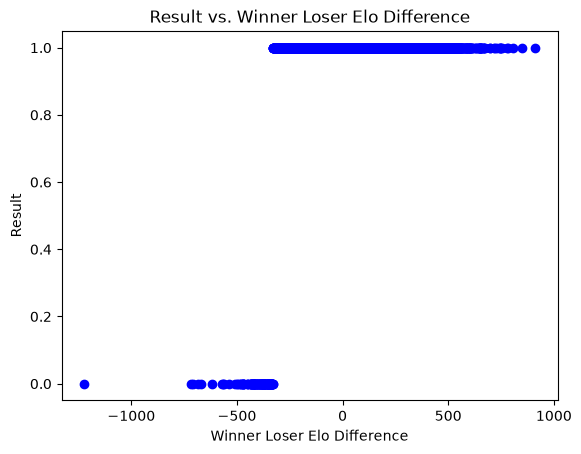

In [3]:
grouped= chess.groupby('event')
classical= grouped.get_group('Rated Classical game')
mapping= {'1-0':1, '0-1':0,'1/2-1/2':np.nan}
classical['result']=classical['result'].replace(mapping)
classical['result']=classical['result'].astype('float')
classical= classical.loc[:,['result', 'winner_loser_elo_diff']]
classical.dropna(how='any', inplace=True)
labels=classical['result']
features=classical['winner_loser_elo_diff']

cl_train_vectors,cl_test_vectors,cl_train_labels,cl_test_labels=train_test_split(features,labels,test_size=.25)
model=sm.Logit(cl_train_labels,sm.add_constant(cl_train_vectors))
result=model.fit()
print(result.summary()) # P values are low for winner_loser_elo_diff, so it must be statisically significant. 

prediction = round(result.predict(sm.add_constant(cl_test_vectors)))
metrics.accuracy_score(y_true = cl_test_labels, y_pred = prediction)
plt.title('Result vs. Winner Loser Elo Difference')
plt.xlabel('Winner Loser Elo Difference')
plt.ylabel('Result')
plt.scatter(cl_test_vectors,prediction, color = 'b')
#According the scatter plot it is predicted that black has to be 200-250 points higher in elo to secure a win against white.  

*Rated Bullet - Maggie*

/opt/miniconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/opt/miniconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


         Current function value: 0.000708
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                 result   No. Observations:                23857
Model:                          Logit   Df Residuals:                    23852
Method:                           MLE   Df Model:                            4
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:                  0.9990
Time:                        10:46:09   Log-Likelihood:                -16.887
converged:                      False   LL-Null:                       -16500.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -4.1304      3.304     -1.250      0.211     -10.606       2.346
game_order            -5.435e-06

/opt/miniconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))


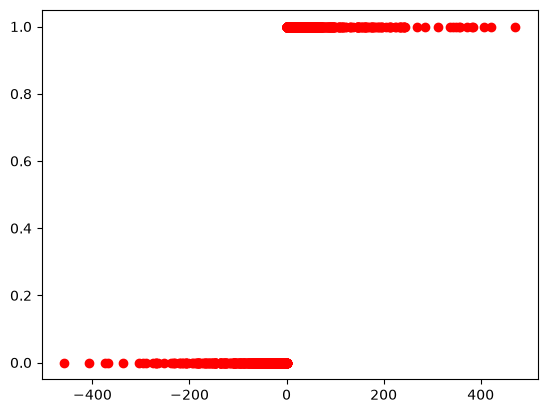

In [78]:
mask = chess['event'] == 'Rated Bullet game'
chess_bullet = chess[mask] #Making a mask so I am just using the bullet data

chess_bullet['result'] = chess_bullet['result'].replace({'1-0':1, '0-1':0, '1/2-1/2':np.nan}) #Changing results to be numerical
chess_bullet['result'] = chess_bullet['result'].astype('float') #Dropping NaN values
chess_bullet = chess_bullet.loc[:,['result','game_order','white_rating_diff','black_rating_diff','winner_loser_elo_diff']]
chess_bullet = chess_bullet.dropna(axis = 0)
labels = chess_bullet['result']
features = chess_bullet.loc[:,['game_order','white_rating_diff','black_rating_diff','winner_loser_elo_diff']]

train_vectors, test_vectors, train_labels, test_labels = train_test_split(features, labels, test_size=.25)

logit_model = sm.Logit(train_labels, sm.add_constant(train_vectors))
result = logit_model.fit() 
print(result.summary())

pred = round(result.predict(sm.add_constant(test_vectors)))
metrics.accuracy_score(y_true = test_labels, y_pred = pred) #Our accuracy is .9991 which is very good!

#Plotting results
plt.scatter(test_vectors['white_rating_diff'],pred, color = 'r')

*Rated Blitz - Zoe*